In [1]:
cd ./wrkDir/s19/s19-1

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [18]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import scipy.optimize as opt
import catutil as utilities
import astropy.io.ascii as ascii

import matplotlib
from matplotlib.ticker import ScalarFormatter
formatter = ScalarFormatter()
formatter.set_scientific(False)
import matplotlib.pyplot as plt
cm  = plt.cm.get_cmap('RdYlBu')
matplotlib.rcParams['xtick.labelsize'] = 'medium'
matplotlib.rcParams['ytick.labelsize'] = 'medium'

import logging
logging.basicConfig(filename='4-ReGaus_Calib.log',level=logging.INFO)

anaDir='./anaCat_newS19Mask_fdeltacut/'
pltDir=os.path.join(anaDir,'plot/reGausCalib')
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim.h5')

# Blinding parameters
add_m_val=0.017
add_a_val=0.

# Whether to remove selection bias
force_90_pair=True

nbin_1d=8
dshape =   (nbin_1d,nbin_1d)

Populating the interactive namespace from numpy and matplotlib


# Preparation
## Add column wlmask_90rot

In [6]:
# Read catalog
dataF =   pd.read_hdf(inFname,mode='r+')
data  =   dataF.to_records(index=True)

min_snr=10
max_snr=800
max_magA10=25.5
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.

if False: # Set to True if you want to change wlmask_90rot
    # Apply **WL_Cut** while cancelling shape noise for simulations
    # NOTE: We are using numpy record to do the selection
    # TODO: Use pandas.DataFrame based in the future
    wlmask    =   utilities.galaxy_selector(catalog=data,
                    min_snr=min_snr, #snr
                    max_snr=max_snr,
                    max_magA10=max_magA10, #magA10
                    min_res=min_res, #res
                    max_mag=max_mag, #mag
                    max_logb=max_logb,#logb
                    force_90_pair=force_90_pair,
                    max_e=max_e,     #absE
                    max_sigma_e=max_sigma_e) #sigma_e
    dataF['wlmask_90rot']=wlmask
else:
    wlmask=data['wlmask_90rot']
data=data[wlmask]

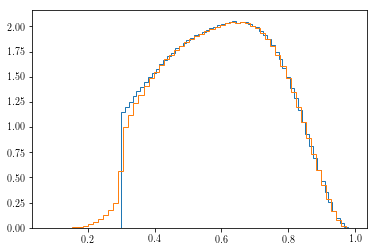

In [4]:
if False:
    # Check the histogram difference between 90-paired sample
    # and non-paired sample
    wlmask2    =   utilities.galaxy_selector(catalog=data,
                    min_snr=min_snr, #snr
                    max_snr=max_snr,
                    max_magA10=max_magA10, #magA10
                    min_res=min_res, #res
                    max_mag=max_mag, #mag
                    max_logb=max_logb,#logb
                    force_90_pair=False,
                    max_e=max_e,     #absE
                    max_sigma_e=max_sigma_e) #sigma_e
    data2=dataF.to_records()[wlmask2]

    plt.hist(data2['res'],bins=60,density=True,histtype='step')
    plt.hist(data['res'],bins=60,density=True,histtype='step')

    if force_90_pair:
        assert np.all(data[0::2]['ipos']==(data['ipos'][1::2]-1))
        assert np.all(data[0::2]['weight']==(data['weight'][1::2]))

## Add column calib_slide_ibins

In [8]:
# Prepare the SNR resolution bins

# We need to get the weight here, to use when averaging over galaxies to get mean effective
# SNR and resolution.
# Note, it might be worth making a utility for this combined shape + S16A weight, since it's
# done here and in estimate_subfield_shear.
shape_weight = utilities.get_weight_model(data)*data['weight']
snr=utilities.get_snr(data)
res=utilities.get_res(data)

def sliding_window_def(snr,res,weights=None,n_gal=100, n_bin_1d=20, snr_overlap=1.4):
    """
    sim_analysis_utilities.sliding_window_def

    A routine to define 2d bins in a sample based on its (snr, res)
    using a sliding window.  
    It returns an array of lower and upper bin
    edges for the overlapping SNR bins, each of length n_bin_1d.  It
    also returns resolution bin edges within each SNR bin, i.e., the
    lower and upper resolution bin edges have shape (n_bin_1d,
    n_bin_1d).

    Parameters
    n_gal: the minimum number of galaxies in a 2d bin, which 
            determines the overlap in res binning
    n_bin_1d: gives the number of bins to use in 1 dimension.  
    snr_overlap: determines the overlap in snr binning. Set
            snr_overlap=1. does not overlap snr bins
    """
    lower_percentiles = np.linspace(0.,100.,n_bin_1d+1)[:-1]
    delta_perc = lower_percentiles[1]-lower_percentiles[0]
    lower_percentiles -= (0.5*(snr_overlap-1.))*delta_perc
    lower_percentiles[0] = 0
    upper_percentiles = np.linspace(0.,100.,n_bin_1d+1)[1:]
    upper_percentiles += (0.5*(snr_overlap-1.))*delta_perc
    upper_percentiles[-1] = 100.
    snr_lower = utilities.weighted_percentile(snr,lower_percentiles,weights)
    snr_upper = utilities.weighted_percentile(snr,upper_percentiles,weights)
    res_lower = np.zeros((n_bin_1d, n_bin_1d))
    res_upper = np.zeros((n_bin_1d, n_bin_1d))
    # Now loop over the bins in SNR.
    for sbin in range(n_bin_1d):
        sbin_mask   = (snr >= snr_lower[sbin]) & \
            (snr < snr_upper[sbin])
        tmp_res = res[sbin_mask]
        if weights  is not None:
            tmp_wt  =   weights[sbin_mask]
        else:
            tmp_wt  =   None
        if len(tmp_res) < 1.1*n_gal:
            raise RuntimeError("Not enough objects to make "+
                               "sliding window")
        # width of bin in percentiles
        delta_perc  =   100.*max(float(n_gal)/len(tmp_res),1./n_bin_1d)
        bounds_percentiles  =   np.linspace(0.,100.,n_bin_1d+1)
        cent_percentiles    =   (bounds_percentiles[:-1]+bounds_percentiles[1:])/2.
        lower_percentiles   =   cent_percentiles - delta_perc/2.
        upper_percentiles   =   lower_percentiles + delta_perc
        lower_percentiles[0]=   0.
        upper_percentiles[-1]=   100.
        res_lower[sbin, :]  =   utilities.weighted_percentile(tmp_res,
                                    lower_percentiles,tmp_wt)
        res_upper[sbin, :]  =   utilities.weighted_percentile(tmp_res,
                                    upper_percentiles,tmp_wt)
    return snr_lower, snr_upper, res_lower, res_upper

# sim_analysis_utilities.make_slide_window
# Determine the Boundary
ngal_bin=20*100*100
snr_lower, snr_upper, res_lower, res_upper = sliding_window_def(snr,res,shape_weight,
    n_gal=ngal_bin,n_bin_1d=nbin_1d)

In [9]:
if True:
    # Record the mean (snr,res) for each bin
    # And also the bin number of each galaxy
    # Fails if total bin number is larger than 64
    slide_calib_bins=np.zeros(len(data),dtype=np.uint64)
    snr_bins = np.zeros((nbin_1d, nbin_1d))
    res_bins = np.zeros((nbin_1d, nbin_1d))
    for j in range(nbin_1d):
        for k in range(nbin_1d):
            tmp_mask = (snr >= snr_lower[j]) & (snr < snr_upper[j]) & \
            (res >= res_lower[j,k]) & (res < res_upper[j,k])
            if force_90_pair:
                tmp_mask[1::2] = tmp_mask[0::2]
            mean_snr = np.sum(shape_weight[tmp_mask]*snr[tmp_mask])/ \
                np.sum(shape_weight[tmp_mask])
            mean_res = np.sum(shape_weight[tmp_mask]*res[tmp_mask])/ \
                np.sum(shape_weight[tmp_mask])
            snr_bins[j,k] = mean_snr
            res_bins[j,k] = mean_res
            slide_calib_bins[tmp_mask]=(slide_calib_bins[tmp_mask]|np.uint64(2**(j*nbin_1d+k)))

    if force_90_pair:        
        assert np.all(slide_calib_bins[0::2]==slide_calib_bins[1::2])

    # Record the column denoting the slide bins with 90 degree rotation
    # which means no selection bias
    dataF['calib_slide_ibins']=np.zeros(len(dataF),dtype=np.uint64)
    dataF['calib_slide_ibins'][wlmask]=slide_calib_bins
    #dataF.to_hdf(inFname,key='data')

/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy


In [12]:
data=dataF.to_records()

fake_x = np.vstack((snr_bins.flatten(), res_bins.flatten()))

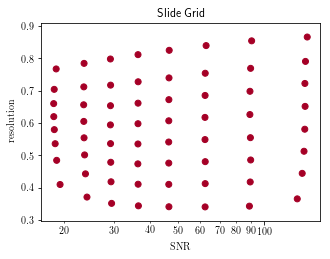

In [10]:
# Make plot
fig = plt.figure(figsize=(5,8))
ax = fig.add_subplot(211)
plt.scatter(snr_bins, res_bins, c=np.ones(res_bins.shape), cmap=cm)
ax.set_xscale('log',basex=10)
ax.set_xlabel(r'\rm{SNR}')
ax.set_ylabel(r'\rm{resolution}')
ax.set_title('Slide Grid')
ax.xaxis.set_minor_formatter(formatter)
ax.xaxis.set_major_formatter(formatter)

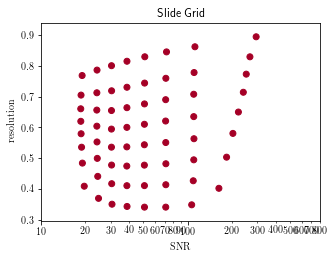

In [13]:
# Make plot
fig = plt.figure(figsize=(5,8))
ax = fig.add_subplot(211)
plt.scatter(snr_bins, res_bins, c=np.ones(res_bins.shape), cmap=cm)
ax.set_xscale('log',basex=10)
ax.set_xlabel(r'\rm{SNR}')
ax.set_xlim(10,800)
ax.set_ylabel(r'\rm{resolution}')
ax.set_title('Slide Grid')
ax.xaxis.set_minor_formatter(formatter)
ax.xaxis.set_major_formatter(formatter)

# Multiplicative bias and Additive bias

## First we run reGaus_shearCalibRun.py
reGaus_shearCalibTask

## Biases in (snr, res) bins

In [3]:
prefix='shear'
# Load outcomes of reGaus_shearCalib.py
shearBinName=   os.path.join(pltDir,'shear_slide_bins_force_weight.npy')
outcomes=np.load(shearBinName)

nsim   =   len(outcomes)
psf_e1 =   np.zeros(nsim)
psf_e2 =   np.zeros(nsim)
weight =   np.zeros(nsim)
g1_true=   np.zeros(nsim)
g2_true=   np.zeros(nsim)
g1_bins=   np.zeros((nbin_1d,nbin_1d,nsim))
g2_bins=   np.zeros((nbin_1d,nbin_1d,nsim))
sigma_g_bins=   np.zeros((nbin_1d,nbin_1d,nsim))

for iout,outcome in enumerate(outcomes):
    g1_true[iout]  =   outcome[0]
    g2_true[iout]  =   outcome[1]
    g1_bins[:,:,iout]  =   outcome[2]
    g2_bins[:,:,iout]  =   outcome[3]
    sigma_g_bins[:,:,iout]  =   outcome[4]
    psf_e1[iout]  =   outcome[5]
    psf_e2[iout]  =   outcome[6]
    weight[iout]  =   outcome[7]

In [10]:
m1_bins    =   np.zeros(dshape)
a1_bins    =   np.zeros(dshape)
sigm1_bins =   np.zeros(dshape)
siga1_bins =   np.zeros(dshape)

# For each of the sliding bins in SNR/resolution.
for j in range(nbin_1d):
    for k in range(nbin_1d):
        sigma_vals = sigma_g_bins[j,k,:]
        division_val = np.sqrt(weight)
        division_val[division_val<1.e-6] = 1.e-6
        sigma_vals /= division_val
        # remove unrealistic sim
        tmp_use = (sigma_vals < 1.e+10)
        # get multiplicative bias and additive bias
        m1_bins[j,k],a1_bins[j,k], \
        sigm1_bins[j,k],siga1_bins[j,k]= \
            utilities.get_m_c_a(g1_bins[j,k,tmp_use],
                                g2_bins[j,k,tmp_use],
                                g1_true[tmp_use],
                                g2_true[tmp_use],
                                psf_e1[tmp_use],
                                psf_e2[tmp_use],
                                sigma_vals[tmp_use],
                                separate_components=False)
        logging.info('Bin %d %d bias analysis:'%(j,k))
        logging.info('m = %.3f +/- %.3f' % (m1_bins[j,k], sigm1_bins[j,k]))
        logging.info('a = %.3f +/- %.3f' % (a1_bins[j,k], siga1_bins[j,k]))
        

#Write data
out_data    =   list(zip(snr_bins.flatten(), res_bins.flatten(),
        m1_bins.flatten(), sigm1_bins.flatten(),
        a1_bins.flatten(), siga1_bins.flatten()))


biasBinFname    =   os.path.join(pltDir,'%s_m_a_2d.csv' %(prefix))
mcBinTab    =   pd.DataFrame(data=out_data,columns=('snr','res','m','mSigma','a','aSigma'))
#mcBinTab.to_csv(biasBinFname)

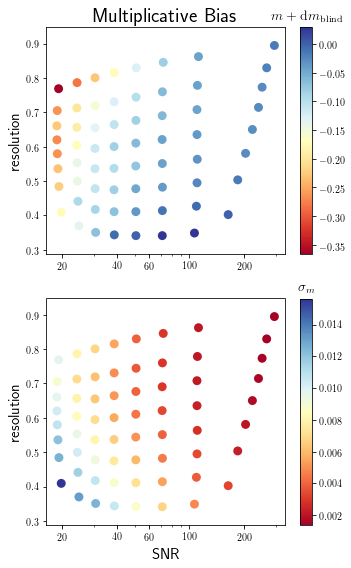

In [22]:
# Plot multiplicative bias in each bins
formatter = ScalarFormatter()
formatter.set_scientific(False)
m_vmin = np.min(m1_bins+add_m_val)
m_vmax = np.max(m1_bins+add_m_val)
fig = plt.figure(figsize=(5,8))
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=m1_bins+add_m_val, cmap=cm,
            vmin=m_vmin, vmax=m_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
if add_m_val > 0:
    cbar.ax.set_title(r'$m+\mathrm{d}m_{\rm blind}$',fontsize=14)
else:
    cbar.ax.set_title(r'$m$',fontsize=14)
ax.set_xscale('log')
ax.set_ylabel('resolution',fontsize=15)
ax.set_title('Multiplicative Bias',fontsize=20)
ax.xaxis.set_major_formatter(formatter)
ax.set_xticks(np.array([20,40,60,100,200]))
ax.set_xticklabels((r'$20$',r'$40$',r'$60$',r'$100$',r'$200$'))

ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins, c=sigm1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$\sigma_m$',fontsize=14)
ax.set_xscale('log')
ax.set_xlabel('SNR',fontsize=15)
ax.set_ylabel('resolution',fontsize=15)
ax.xaxis.set_major_formatter(formatter)
ax.set_xticks(np.array([20,40,60,100,200]))
ax.set_xticklabels((r'$20$',r'$40$',r'$60$',r'$100$',r'$200$'))

plt.tight_layout()
plt.savefig(os.path.join(pltDir,'%s_m_2d.eps'%(prefix)))

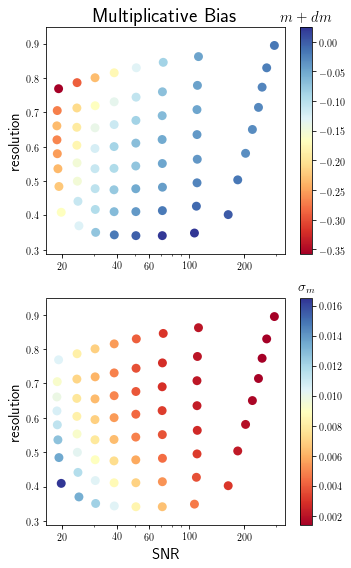

In [19]:
# Plot multiplicative bias in each bins
formatter = ScalarFormatter()
formatter.set_scientific(False)
m_vmin = np.min(m1_bins+add_m_val)
m_vmax = np.max(m1_bins+add_m_val)
fig = plt.figure(figsize=(5,8))
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=m1_bins+add_m_val, cmap=cm,
            vmin=m_vmin, vmax=m_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
if add_m_val > 0:
    cbar.ax.set_title(r'$m+dm$',fontsize=15)
else:
    cbar.ax.set_title(r'$m$',fontsize=15)
ax.set_xscale('log')
ax.set_ylabel('resolution',fontsize=15)
ax.set_title('Multiplicative Bias',fontsize=20)
ax.xaxis.set_major_formatter(formatter)
ax.set_xticks(np.array([20,40,60,100,200]))
ax.set_xticklabels((r'$20$',r'$40$',r'$60$',r'$100$',r'$200$'))

ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins, c=sigm1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$\sigma_m$',fontsize=14)
ax.set_xscale('log')
ax.set_xlabel('SNR',fontsize=15)
ax.set_ylabel('resolution',fontsize=15)
ax.xaxis.set_major_formatter(formatter)
ax.set_xticks(np.array([20,40,60,100,200]))
ax.set_xticklabels((r'$20$',r'$40$',r'$60$',r'$100$',r'$200$'))

plt.tight_layout()
plt.savefig(os.path.join(pltDir,'%s_m_2d.eps'%(prefix)))

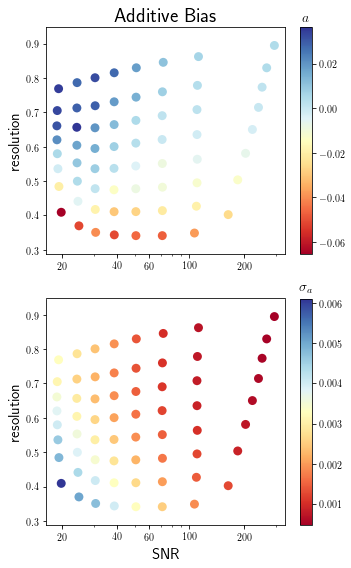

In [23]:
# Plot additive bias in each bin
a_vmin = np.min(a1_bins+add_a_val)
a_vmax = np.max(a1_bins+add_a_val)
fig = plt.figure(figsize=(5,8))
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=a1_bins+add_a_val, cmap=cm,vmin=a_vmin, vmax=a_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
ax.set_xscale('log')
ax.set_ylabel('resolution',fontsize=15)
ax.set_title('Additive Bias',fontsize=20)
if add_a_val > 0:
    cbar.ax.set_title(r'$a+\mathrm{d}a_{\rm blind}$',fontsize=14)
else:
    cbar.ax.set_title(r'$a$' ,fontsize=14)
ax.xaxis.set_major_formatter(formatter)
ax.set_xticks(np.array([20,40,60,100,200]))
ax.set_xticklabels((r'$20$',r'$40$',r'$60$',r'$100$',r'$200$'))

# Also plot errors in this case.
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins, c=siga1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$\sigma_a$',fontsize=14)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(formatter)
ax.set_xticks(np.array([20,40,60,100,200]))
ax.set_xticklabels((r'$20$',r'$40$',r'$60$',r'$100$',r'$200$'))
ax.set_xlabel('SNR',fontsize=15)
ax.set_ylabel('resolution',fontsize=15)

plt.tight_layout()
plt.savefig(os.path.join(pltDir,'%s_a_2d.eps'%(prefix)))

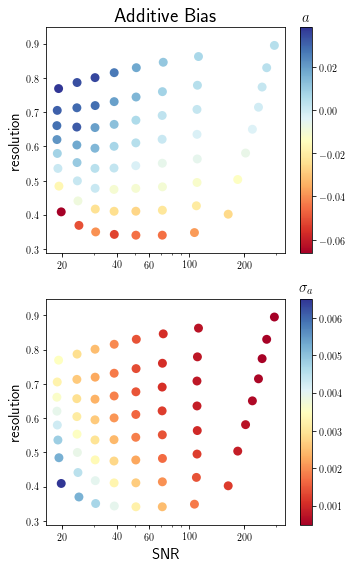

In [20]:
# Plot additive bias in each bin
a_vmin = np.min(a1_bins+add_a_val)
a_vmax = np.max(a1_bins+add_a_val)
fig = plt.figure(figsize=(5,8))
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=a1_bins+add_a_val, cmap=cm,vmin=a_vmin, vmax=a_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
ax.set_xscale('log')
ax.set_ylabel('resolution',fontsize=15)
ax.set_title('Additive Bias',fontsize=20)
if add_a_val > 0:
    cbar.ax.set_title(r'$m+$constant',fontsize=15)
else:
    cbar.ax.set_title(r'$a$' ,fontsize=15)
ax.xaxis.set_major_formatter(formatter)
ax.set_xticks(np.array([20,40,60,100,200]))
ax.set_xticklabels((r'$20$',r'$40$',r'$60$',r'$100$',r'$200$'))

# Also plot errors in this case.
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins, c=siga1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$\sigma_a$',fontsize=15)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(formatter)
ax.set_xticks(np.array([20,40,60,100,200]))
ax.set_xticklabels((r'$20$',r'$40$',r'$60$',r'$100$',r'$200$'))
ax.set_xlabel('SNR',fontsize=15)
ax.set_ylabel('resolution',fontsize=15)

plt.tight_layout()
plt.savefig(os.path.join(pltDir,'%s_a_2d.eps'%(prefix)))

## Modelling Biases

In [32]:
# Fitting
outMA   =   {}

# Model fitting for multiplicative bias
m_opt, m_cov = opt.curve_fit(
    utilities.m_func, fake_x, m1_bins.flatten(), sigma=sigm1_bins.flatten(),
    bounds=([-np.inf,0,-np.inf,-np.inf],[np.inf,np.inf,0,np.inf]))

outMA.update({'m_opt':m_opt,'m_cov':m_cov})
if True:
    print('m model:')
    print('m=b*(res/0.5)^c*(snr/20)^d+e')
    for ind in range(len(m_opt)):
        print('%f +/- %f'%(m_opt[ind],m_cov[ind,ind]))

# For additive bias
a_opt, a_cov = opt.curve_fit(
    utilities.a_func, fake_x, a1_bins.flatten(), sigma=siga1_bins.flatten(),
    bounds=([-np.inf,-np.inf,-np.inf],[np.inf,np.inf,0.]))

outMA.update({'a_opt':a_opt,'a_cov':a_cov})

if True:
    print('a model:')
    print('a=b*(res-c)*(snr/20)^d')
    for ind in range(len(a_opt)):
        print('%f +/- %f'%(a_opt[ind],a_cov[ind,ind]))

# Save results
maFname  =   os.path.join(pltDir,'%s_m_a_model_par.npy'%(prefix))
np.save(maFname,outMA)

m model:
m=b*(res/0.5)^c*(snr/20)^d+e
-0.164479 +/- 0.000116
1.525240 +/- 0.028793
-1.131625 +/- 0.007305
-0.017605 +/- 0.000038
a model:
a=b*(res-c)*(snr/20)^d
0.255368 +/- 0.001326
0.609995 +/- 0.000125
-0.959729 +/- 0.017404


In [24]:
# Fitting
outMA   =   {}

# Model fitting for multiplicative bias
m_opt, m_cov = opt.curve_fit(
    utilities.m_func, fake_x, m1_bins.flatten(), sigma=sigm1_bins.flatten(),
    bounds=([-np.inf,0,-np.inf,-np.inf],[np.inf,np.inf,0,np.inf]))

outMA.update({'m_opt':m_opt,'m_cov':m_cov})
if True:
    print('m model:')
    print('m=b*(res/0.5)^c*(snr/20)^d+e')
    for ind in range(len(m_opt)):
        print('%f +/- %f'%(m_opt[ind],m_cov[ind,ind]))

# For additive bias
a_opt, a_cov = opt.curve_fit(
    utilities.a_func, fake_x, a1_bins.flatten(), sigma=siga1_bins.flatten(),
    bounds=([-np.inf,-np.inf,-np.inf],[np.inf,np.inf,0.]))

outMA.update({'a_opt':a_opt,'a_cov':a_cov})

if True:
    print('a model:')
    print('a=b*(res-c)*(snr/20)^d')
    for ind in range(len(a_opt)):
        print('%f +/- %f'%(a_opt[ind],a_cov[ind,ind]))

# Save results
maFname  =   os.path.join(pltDir,'%s_m_a_model_par.npy'%(prefix))
np.save(maFname,outMA)

m model:
m=b*(res/0.5)^c*(snr/20)^d+e
-0.154424 +/- 0.000079
1.655072 +/- 0.027023
-1.237928 +/- 0.005581
-0.025573 +/- 0.000011
a model:
a=b*(res-c)*(snr/20)^d
0.240531 +/- 0.001274
0.605817 +/- 0.000159
-0.941596 +/- 0.014706


### S19A-v2
$$m \sim (\frac{\rm{res}}{0.5})^{1.53}(\frac{\rm{snr}}{20})^{-1.13} + \rm{constant}$$
$$a \sim (\rm{res}-0.61)(\frac{\rm{snr}}{20})^{-0.96}$$

### S19A
$$m \sim (\frac{\rm{res}}{0.5})^{1.53}(\frac{\rm{snr}}{20})^{-1.13} + \rm{constant}$$
$$a \sim (\rm{res}-0.61)(\frac{\rm{snr}}{20})^{-0.96}$$

### S16A
$$m \sim (\frac{\rm{res}}{0.5})^{1.23}(\frac{\rm{snr}}{20})^{-1.24} + \rm{constant}$$
$$a \sim (\rm{res}-0.51)(\frac{\rm{snr}}{20})^{-1.07}$$

Text(0.5, 1.0, 'Modelled Multiplicative Bias')

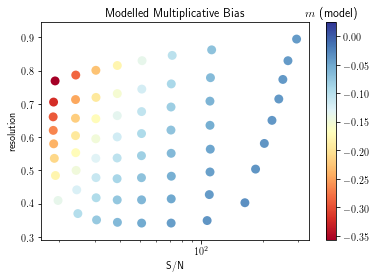

In [25]:
# Plot multiplicative bias model
m_vmin = np.min(m1_bins+add_m_val)
m_vmax = np.max(m1_bins+add_m_val)
m_opt   =   outMA['m_opt']
# plot the model, residuals, and their significance
m_model =   utilities.m_func(fake_x, *m_opt).reshape(dshape)


fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(snr_bins, res_bins, c=m_model, cmap=cm,
            vmin=m_vmin, vmax=m_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$m$ (model)')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Modelled Multiplicative Bias')
#plt.savefig(pltDir+'%s_m_model_2d.png'%(prefix))

Text(0.5, 1.0, 'Modelled Additive Bias')

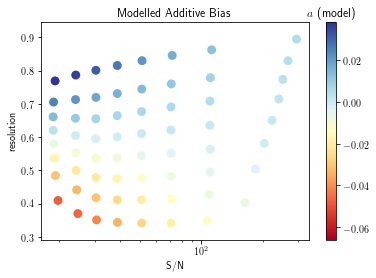

In [26]:
# Plot multiplicative bias model
a_vmin = np.min(a1_bins+add_a_val)
a_vmax = np.max(a1_bins+add_a_val)
a_opt   =   outMA['a_opt']
# plot the model, residuals, and their significance
a_model =   utilities.a_func(fake_x, *a_opt).reshape(dshape)


fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(snr_bins, res_bins, c=a_model, cmap=cm,
            vmin=a_vmin, vmax=a_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$a$ (model)')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Modelled Additive Bias')
#plt.savefig(pltDir+'%s_m_model_2d.png'%(prefix))

## Model Residuals
We need to further correct for the residuals of the pwoer law modelling.

In [27]:
# Record the mean dm dc for each bin
df_x=np.vstack((data['snr'],data['res']))
model_m =   utilities.m_func(df_x,*m_opt)
model_a =   utilities.a_func(df_x,*a_opt)
shape_weight = utilities.get_weight_model(data)*data['weight']

m_mres_bins = np.zeros((nbin_1d, nbin_1d))
a_mres_bins = np.zeros((nbin_1d, nbin_1d))
for j in range(nbin_1d):
    for k in range(nbin_1d):
        sbin=j*nbin_1d+k
        mask=(np.int_(data['calib_slide_ibins'])==2**sbin)
        sum_weight=np.sum(shape_weight[mask])
        sum_m=np.sum(model_m[mask]*shape_weight[mask])
        sum_a=np.sum(model_a[mask]*shape_weight[mask])
        m_mres_bins[j,k] =sum_m/sum_weight
        a_mres_bins[j,k] =sum_a/sum_weight
m_mres_bins=m1_bins-m_mres_bins
a_mres_bins=a1_bins-a_mres_bins

/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in double_scalars
  app.launch_new_instance()
/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:17: RuntimeWarning: invalid value encountered in double_scalars


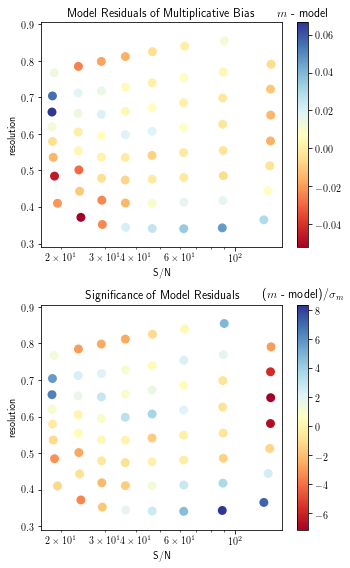

In [36]:
fig = plt.figure(figsize=(5,8))

# Plot residuals
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=m_mres_bins,
            cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$m$ - model')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Model Residuals of Multiplicative Bias ')

# Plot significance
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins,
            c=m_mres_bins/sigm1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'($m$ - model)/$\sigma_m$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Significance of Model Residuals')
plt.tight_layout()
#plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))

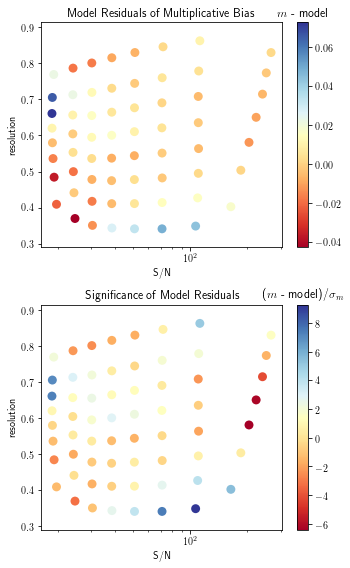

In [28]:
fig = plt.figure(figsize=(5,8))

# Plot residuals
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=m_mres_bins,
            cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$m$ - model')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Model Residuals of Multiplicative Bias ')

# Plot significance
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins,
            c=m_mres_bins/sigm1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'($m$ - model)/$\sigma_m$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Significance of Model Residuals')
plt.tight_layout()
#plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))

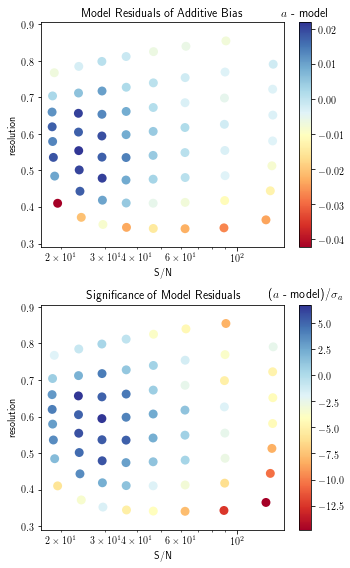

In [37]:
fig = plt.figure(figsize=(5,8))
# residuals
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins,res_bins,c=a_mres_bins,
                cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$a$ - model')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Model Residuals of Additive Bias')

# Plot significance
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins,
            c=a_mres_bins/siga1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'($a$ - model)/$\sigma_a$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Significance of Model Residuals')
plt.tight_layout()

#plt.savefig(pltDir+'%s_Delta_a_model_2d.png'%(prefix))

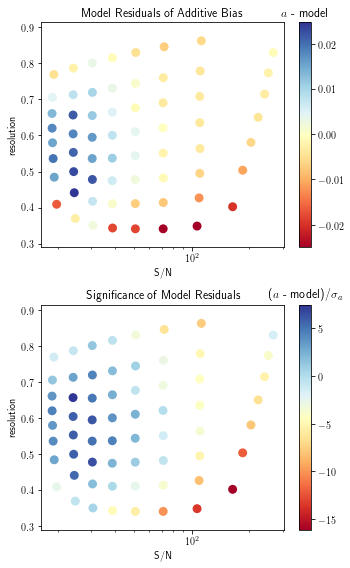

In [29]:
fig = plt.figure(figsize=(5,8))
# residuals
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins,res_bins,c=a_mres_bins,
                cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$a$ - model')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Model Residuals of Additive Bias')

# Plot significance
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins,
            c=a_mres_bins/siga1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'($a$ - model)/$\sigma_a$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Significance of Model Residuals')
plt.tight_layout()

#plt.savefig(pltDir+'%s_Delta_a_model_2d.png'%(prefix))

In [30]:
# Write /delta m /delta a to csv file 
out_data=list(zip(snr_bins.flatten(), res_bins.flatten(),
        m_mres_bins.flatten(), sigm1_bins.flatten(),
        a_mres_bins.flatten(), siga1_bins.flatten()))
mcDeltaBinTab    =   pd.DataFrame(data=out_data,columns=('snr','res','dm','mSigma','da','aSigma'))
mcDeltaBinTab.to_csv(os.path.join(pltDir,'%s_dm_da_2d.csv'%(prefix)))

# Simple Sanity Tests

In [31]:
dataF=dataF[dataF['wlmask_90rot']]
indexS=  dataF.index.levels[1]
indexList= ascii.read('info_newS19Mask_fd001_sim.csv')['num']
mask=np.in1d(indexList,indexS)
indexList=indexList[mask]

test_weight_bias=False
outData=[]
for index in indexList:
    catalog =   dataF.xs(index,level='isim').to_records(index=False)
    reweight     =   catalog['weight'][0]
    if len(catalog)<50 or reweight<1.e-6:
        continue
    # Force the same weight and Response
    e_rms = utilities.get_erms_model(catalog)
    shape_weights = utilities.get_weight_model(catalog)*catalog['weight']
    if not test_weight_bias:
        shape_weights[1::2] = shape_weights[0::2]
        e_rms[1::2] = e_rms[0::2]
    
    # True shear
    g1_true, g2_true= utilities.get_true_shear(catalog[0])
    # PSF shapes
    psf_e1, psf_e2  =   utilities.get_psf_ellip(catalog[0])
    # Shear Estimation
    e1,e2   =   utilities.get_gal_ellip(catalog)
    shear_num_1 = np.sum(shape_weights * e1)
    shear_num_2 = np.sum(shape_weights * e2)
    sum_weight = np.sum(shape_weights)
    # Calibration
    if True:
        model_m = utilities.get_m_model(catalog,weight_bias=test_weight_bias, photo_z_dep=False)
        model_c1,model_c2 = utilities.get_c_model(catalog,weight_bias=test_weight_bias, photo_z_dep=False)
    else:
        model_m = m1_bins.flatten()[np.int_(catalog['calib_slide_ibins'])]
        model_a=  a1_bins.flatten()[np.int_(catalog['calib_slide_ibins'])]
        model_c1= model_a*psf_e1
        model_c2= model_a*psf_e2
    bias_num = np.sum(shape_weights*model_m)
    add_num_1 = np.sum(shape_weights*model_c1)
    add_num_2 = np.sum(shape_weights*model_c2)
    bias = bias_num / sum_weight
    resp_num = np.sum(shape_weights * e_rms**2)
    responsivity = 1.0 - resp_num/sum_weight

    g1 = shear_num_1 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_1/((1.0+bias)*sum_weight)
    g2 = shear_num_2 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_2/((1.0+bias)*sum_weight)
    sigma= 0.25/np.sqrt(len(catalog))
    
    oDat    =   (g1_true,g2_true,g1,g2,sigma,psf_e1,psf_e2,reweight)
    outData.append(oDat)

In [32]:
odf=pd.DataFrame(outData,columns=('g1_true','g2_true','g1','g2','sigma','psf_e1','psf_e2','reweight')).to_records()
division_val = np.sqrt(odf['reweight'])
division_val[division_val<1.e-6] = 1.e-6
odf['sigma'] /= division_val
# remove unrealistic sim
odf=odf[(odf['sigma'] < 1.e+6)]
# get multiplicative bias and additive bias
m1,a1,sigm1,siga1= utilities.get_m_c_a(
    odf['g1'],odf['g2'],
    odf['g1_true'],odf['g2_true'],
    odf['psf_e1'],odf['psf_e2'],
    odf['sigma'],separate_components=False)
print('m = %.4f +/- %.4f' % (m1, sigm1))
print('a = %.4f +/- %.4f' % (a1, siga1))

m = -0.0002 +/- 0.0016
a = -0.0005 +/- 0.0006
